# **1. Pôster: as arquibancadas da previsão**

Este notebook transforma a ablação por clube do notebook 05 numa peça visual para os 20 clubes da Série A 2026. Cada clube vira um estádio visto de cima, com o escudo no centro. Os cinco setores da arquibancada são os grupos de variáveis do modelo, e a torcida, na cor do clube, ocupa cada setor na medida em que o grupo reduz o erro da previsão daquele clube.

| etapa | fonte | resultado |
|---|---|---|
| clubes de 2026 | `data/processed/features.csv` | os 20 clubes com jogos em casa na temporada 2026 |
| escudos | logotipos públicos da ESPN | um PNG por clube em `data/raw/escudos/` |
| ablação | `data/processed/ablation/match_errors.csv` | aumento do erro de cada clube sem cada grupo, com bootstrap |
| pôster | estádios desenhados em matplotlib | `viz/7_01_arquibancadas_serie_a_2026.png` |

A leitura da peça segue o notebook 05: o valor de cada setor é o aumento do erro médio do clube nas temporadas de teste (2025 e 2026) quando o grupo é retirado do modelo. Quatro clubes de 2026 têm menos de 12 jogos de teste (Athletico-PR, Chapecoense, Coritiba e Remo); eles ficam de fora das tabelas do notebook 05, mas entram aqui com a indicação de amostra pequena.

In [1]:
from __future__ import annotations

import textwrap
import time
from io import BytesIO
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import Image as IPImage
from IPython.display import display
from matplotlib import font_manager as fm
from matplotlib.colors import to_rgb
from matplotlib.offsetbox import AnnotationBbox, OffsetImage
from matplotlib.patches import Ellipse, Polygon
from PIL import Image

### **1.1. Configuração**

As fontes ficam em `assets/fonts/` (Alfa Slab One para títulos e Saira Condensed para o texto, ambas sob a licença SIL Open Font License). As cores de cada clube foram definidas à mão a partir do uniforme principal; clubes de camisa preta e branca usam um preto quente.

In [2]:
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

PROCESSED = ROOT / "data" / "processed"
CREST_DIR = ROOT / "data" / "raw" / "escudos"
VIZ = ROOT / "viz"
CREST_DIR.mkdir(parents=True, exist_ok=True)
VIZ.mkdir(parents=True, exist_ok=True)
POSTER = "7_01_arquibancadas_serie_a_2026.png"

for font in (ROOT / "assets" / "fonts").glob("*.ttf"):
    fm.fontManager.addfont(str(font))
FONT = "Saira Condensed"
DISPLAY = "Alfa Slab One"

SEASON = 2026
GROUPS = ["opponent", "venue", "form", "calendar", "weather"]
NAME = {"opponent": "Adversário", "venue": "Estádio", "form": "Momento", "calendar": "Calendário", "weather": "Clima"}
N_BOOT = 2000
SEED = 7

features = pd.read_csv(PROCESSED / "features.csv")
errors = pd.read_csv(PROCESSED / "ablation" / "match_errors.csv")
overall = pd.read_csv(PROCESSED / "ablation" / "overall.csv", index_col=0)
club_map = pd.read_csv(PROCESSED / "club_map.csv").dropna(subset=["espn_id"]).drop_duplicates("espn_id").set_index("club")["espn_id"].astype(int)
CLUBS = sorted(features.loc[features["season"].eq(SEASON), "home"].unique())

CLUB_COLOR = {
    "Athletico-PR": "#c8102e", "Atlético-MG": "#1f1f1f", "Bahia": "#0b5cad", "Botafogo": "#1f1f1f", "Chapecoense": "#0a8a43",
    "Corinthians": "#1f1f1f", "Coritiba": "#00594c", "Cruzeiro": "#1c3fa8", "Flamengo": "#c8161d", "Fluminense": "#7d1533",
    "Grêmio": "#1489c9", "Internacional": "#d3121b", "Mirassol": "#e3a900", "Palmeiras": "#0b6a3b", "Red Bull Bragantino": "#d71920",
    "Remo": "#132a5e", "Santos": "#1f1f1f", "São Paulo": "#d1121c", "Vasco da Gama": "#1f1f1f", "Vitória": "#c8102e",
}
SHORT = {"Red Bull Bragantino": "Bragantino", "Vasco da Gama": "Vasco"}
missing_colors = sorted(set(CLUBS) - set(CLUB_COLOR))
assert not missing_colors, f"Clubes sem cor definida: {missing_colors}"
print(f"clubes da temporada {SEASON}: {len(CLUBS)}")

clubes da temporada 2026: 20


## **2. Escudos**

Os escudos vêm dos logotipos públicos da ESPN, indexados pelo mesmo identificador usado como chave canônica dos clubes. Cada arquivo é baixado uma única vez e guardado em `data/raw/escudos/`, pasta que não é versionada.

In [3]:
LOGO_URL = "https://a.espncdn.com/i/teamlogos/soccer/500/{espn_id}.png"
HEADERS = {"User-Agent": "academic-research/brasileirao-attendance-forecasting"}

for club in CLUBS:
    path = CREST_DIR / f"{club_map[club]}.png"
    if path.exists():
        continue
    response = requests.get(LOGO_URL.format(espn_id=club_map[club]), headers=HEADERS, timeout=45)
    response.raise_for_status()
    path.write_bytes(response.content)
    time.sleep(0.3)

crests = pd.Series({club: (CREST_DIR / f"{club_map[club]}.png").exists() for club in CLUBS}, name="escudo")
print(f"escudos disponíveis: {crests.sum()} de {len(crests)}")

escudos disponíveis: 20 de 20


## **3. Ablação dos clubes de 2026**

Para cada clube e cada grupo exógeno, o aumento do erro é a diferença média entre o erro do modelo sem o grupo e o erro do modelo completo, dividida pelo erro do modelo completo, nos jogos de teste do clube. O bootstrap pareado sobre esses jogos dá a proporção de reamostragens em que o grupo reduz o erro; abaixo de 0,9, os assentos aparecem em tom claro. O grupo mais útil de cada clube define a faixa em que ele aparece no pôster.

In [4]:
rng = np.random.default_rng(SEED)
rows = []
for club in CLUBS:
    frame = errors[errors["home"].eq(club)]
    base = frame["full"].to_numpy()
    index = rng.integers(0, len(frame), size=(N_BOOT, len(frame)))
    for group in GROUPS:
        diff = frame[f"without_{group}"].to_numpy() - base
        rows.append({"club": club, "group": group, "matches": len(frame), "increase": diff.mean() / base.mean(), "share": float((diff[index].mean(axis=1) > 0).mean())})
table = pd.DataFrame(rows)
increase = table.pivot(index="club", columns="group", values="increase")[GROUPS]
share = table.pivot(index="club", columns="group", values="share")[GROUPS]
matches = table.groupby("club")["matches"].first()
best = increase.idxmax(axis=1)

summary = pd.DataFrame({"jogos": matches, "grupo_mais_util": best.map(NAME), "aumento_do_erro": [increase.loc[c, g] for c, g in best.items()]})
display(summary.sort_values(["grupo_mais_util", "aumento_do_erro"], ascending=[True, False]).round(3))
display(summary["grupo_mais_util"].value_counts().to_frame("clubes"))

,jogos,grupo_mais_util,aumento_do_erro
club,,,
Mirassol,30,Adversário,0.527
Red Bull Bragantino,27,Adversário,0.350
Corinthians,29,Adversário,0.163
Fluminense,28,Adversário,0.070
Chapecoense,11,Calendário,0.193
Botafogo,27,Calendário,0.111
Grêmio,28,Calendário,0.109
Remo,8,Calendário,0.083
Athletico-PR,9,Calendário,0.060


,clubes
grupo_mais_util,
Estádio,7
Calendário,6
Adversário,4
Momento,3


## **4. Desenho dos estádios**

Cada estádio é uma superelipse vista de cima. O campo é um oval liso com o escudo; em volta, oito fileiras de assentos por setor, com corredores entre os setores e refletores nos quatro cantos. Uma fileira cheia equivale a 5% a mais de erro quando o grupo é retirado, e a ocupação de uma fileira incompleta fica centrada no setor. Cada torcedor recebe uma pequena variação de tom da cor do clube, para que a torcida não pareça um bloco chapado.

In [5]:
BG = "#efeae1"
INK = "#1b1a18"
MUTED = "#7b7468"
CONCRETE = "#ddd5c6"
EMPTY = "#d6cebf"
STAND = "#ebe6dc"
FIELD = "#f7f4ee"
ACCENT = "#c8553d"
GLOW = "#f2c14e"
ROWS = 8
ROW_VALUE = 0.05
SECTOR_CENTER = {"opponent": 90, "venue": 18, "form": -54, "calendar": -126, "weather": -198}
SECTOR_HALF = 31
DPI = 200
CROWD_RNG = np.random.default_rng(11)


def mix(color, amount, base=BG):
    c, b = np.array(to_rgb(color)), np.array(to_rgb(base))
    return tuple(c * (1 - amount) + b * amount)


def superellipse(t, a, b, n=2.6):
    c, s = np.cos(t), np.sin(t)
    return a * np.sign(c) * np.abs(c) ** (2 / n), b * np.sign(s) * np.abs(s) ** (2 / n)


def ring_axes(level, s):
    """Semieixos do anel no nível 0 (borda do campo) até 1 (borda externa)."""
    a0, b0, a1, b1 = 0.64 * s, 0.43 * s, 1.0 * s, 0.76 * s
    return a0 + (a1 - a0) * level, b0 + (b1 - b0) * level


def arc(cx, cy, t, level, s):
    a, b = ring_axes(level, s)
    x, y = superellipse(t, a, b)
    return cx + x, cy + y


def sector_polygon(cx, cy, t0, t1, l0, l1, s):
    t = np.linspace(t0, t1, 60)
    xi, yi = arc(cx, cy, t, l0, s)
    xo, yo = arc(cx, cy, t[::-1], l1, s)
    return np.column_stack([np.r_[xi, xo], np.r_[yi, yo]])


def arc_length(x, y):
    return np.r_[0, np.cumsum(np.hypot(np.diff(x), np.diff(y)))]


def draw_seats(ax, cx, cy, t0, t1, level, s, fraction, color, seat_pt, empty=EMPTY):
    """Uma fileira de assentos; a parte ocupada fica centrada no setor."""
    t = np.linspace(t0, t1, 200)
    x, y = arc(cx, cy, t, level, s)
    length = arc_length(x, y)
    seat = 0.047 * s
    n = max(int(length[-1] / seat), 1)
    positions = (np.arange(n) + 0.5) / n * length[-1]
    occupied = np.zeros(n, dtype=bool)
    k = int(round(fraction * n))
    if k:
        start = (n - k) // 2
        occupied[start:start + k] = True
    for state, col in ((False, empty), (True, color)):
        p = positions[occupied == state]
        if not len(p):
            continue
        px, py = np.interp(p, length, x), np.interp(p, length, y)
        if state:
            base_rgb = np.array(to_rgb(col))
            shade = CROWD_RNG.uniform(-0.16, 0.16, size=(len(p), 1))
            colors = np.clip(np.where(shade > 0, base_rgb + (1 - base_rgb) * shade, base_rgb * (1 + shade)), 0, 1)
            if base_rgb.max() < 0.2:
                colors = np.clip(base_rgb + CROWD_RNG.uniform(0, 0.22, size=(len(p), 1)), 0, 1)
            ax.scatter(px, py, s=seat_pt ** 2, marker="s", c=colors, linewidths=0, zorder=4)
        else:
            ax.scatter(px, py, s=seat_pt ** 2, marker="s", color=col, linewidths=0, zorder=4)


def crest(ax, club, xy, size_in):
    image = Image.open(CREST_DIR / f"{club_map[club]}.png").convert("RGBA")
    image.thumbnail((400, 400))
    zoom = size_in * 72 / max(image.size) * (DPI / 72)
    ax.add_artist(AnnotationBbox(OffsetImage(np.asarray(image), zoom=zoom * 72 / DPI), xy, frameon=False, zorder=8))


def stadium(ax, cx, cy, s, values, shares, color, club=None, best_group=None, labels=False, show_best_value=True):
    # sombra, refletores, anel externo e campo
    t = np.linspace(0, 2 * np.pi, 300)
    xs_, ys_ = arc(cx + 0.05 * s, cy - 0.07 * s, t, 1.09, s)
    ax.add_patch(Polygon(np.column_stack([xs_, ys_]), closed=True, fc=(0.2, 0.17, 0.12, 0.10), ec="none", zorder=0.5))
    for angle in (38, 142, 218, 322):
        mx, my = arc(cx, cy, np.deg2rad(angle), 1.2, s)
        ax.add_patch(Ellipse((mx, my), 0.26 * s, 0.26 * s, fc=GLOW, ec="none", alpha=0.16, zorder=0.6))
        ax.add_patch(Ellipse((mx, my), 0.13 * s, 0.13 * s, fc=GLOW, ec="none", alpha=0.3, zorder=0.6))
        ax.add_patch(plt.Rectangle((mx - 0.032 * s, my - 0.032 * s), 0.064 * s, 0.064 * s, fc=mix(INK, 0.25), ec="none", zorder=0.7))
    xr, yr = arc(cx, cy, t, 1.07, s)
    ax.add_patch(Polygon(np.column_stack([xr, yr]), closed=True, fc=CONCRETE, ec=mix(INK, 0.72), lw=0.8, zorder=1))
    xf, yf = superellipse(t, 0.6 * s, 0.39 * s, n=2.2)
    ax.add_patch(Polygon(np.column_stack([cx + xf, cy + yf]), closed=True, fc=FIELD, ec=mix(INK, 0.7), lw=0.7 * s, zorder=2))
    seat_pt = 0.036 * s * 72
    for group in GROUPS:
        c = np.deg2rad(SECTOR_CENTER[group])
        t0, t1 = c - np.deg2rad(SECTOR_HALF), c + np.deg2rad(SECTOR_HALF)
        ax.add_patch(Polygon(sector_polygon(cx, cy, t0, t1, -0.02, 1.02, s), closed=True, fc=STAND, ec="none", zorder=3))
        value = values.get(group, 0.0)
        filled_rows = max(value, 0) / ROW_VALUE
        strong = shares.get(group, 1.0) >= 0.9
        seat_color = color if strong else mix(color, 0.58)
        for r in range(ROWS):
            level = (r + 0.5) / ROWS
            fraction = float(np.clip(filled_rows - r, 0, 1))
            draw_seats(ax, cx, cy, t0, t1, level, s, fraction, seat_color, seat_pt)
        if group == best_group:
            ax.add_patch(Polygon(sector_polygon(cx, cy, t0 - 0.03, t1 + 0.03, -0.06, 1.06, s), closed=True, fc="none", ec=INK, lw=1.1 * s, zorder=5))
            if show_best_value:
                lx, ly = arc(cx, cy, c, 1.36, s)
                ax.text(lx, ly, f"+{value * 100:.0f}%", ha="center", va="center", fontsize=11 * s, fontweight="bold", color=INK, family=FONT, zorder=6)
        if labels:
            lx, ly = arc(cx, cy, c, 1.55, s)
            ax.text(lx, ly, NAME[group].upper(), ha="center", va="center", fontsize=7.2 * s, fontweight="bold", color=INK, family=FONT)
    if club:
        crest(ax, club, (cx, cy), 0.5 * s)

## **5. Composição do pôster**

O pôster tem quatro faixas, uma por grupo mais útil, em ordem decrescente de clubes; o comprimento de cada faixa já mostra quantos clubes dependem daquele grupo. Dentro da faixa, os clubes seguem o aumento do erro, do maior para o menor. O resumo da liga inteira fica no cabeçalho, e o estádio-chave com as anotações e o bloco "como ler" ocupam o espaço ao lado das faixas mais curtas.

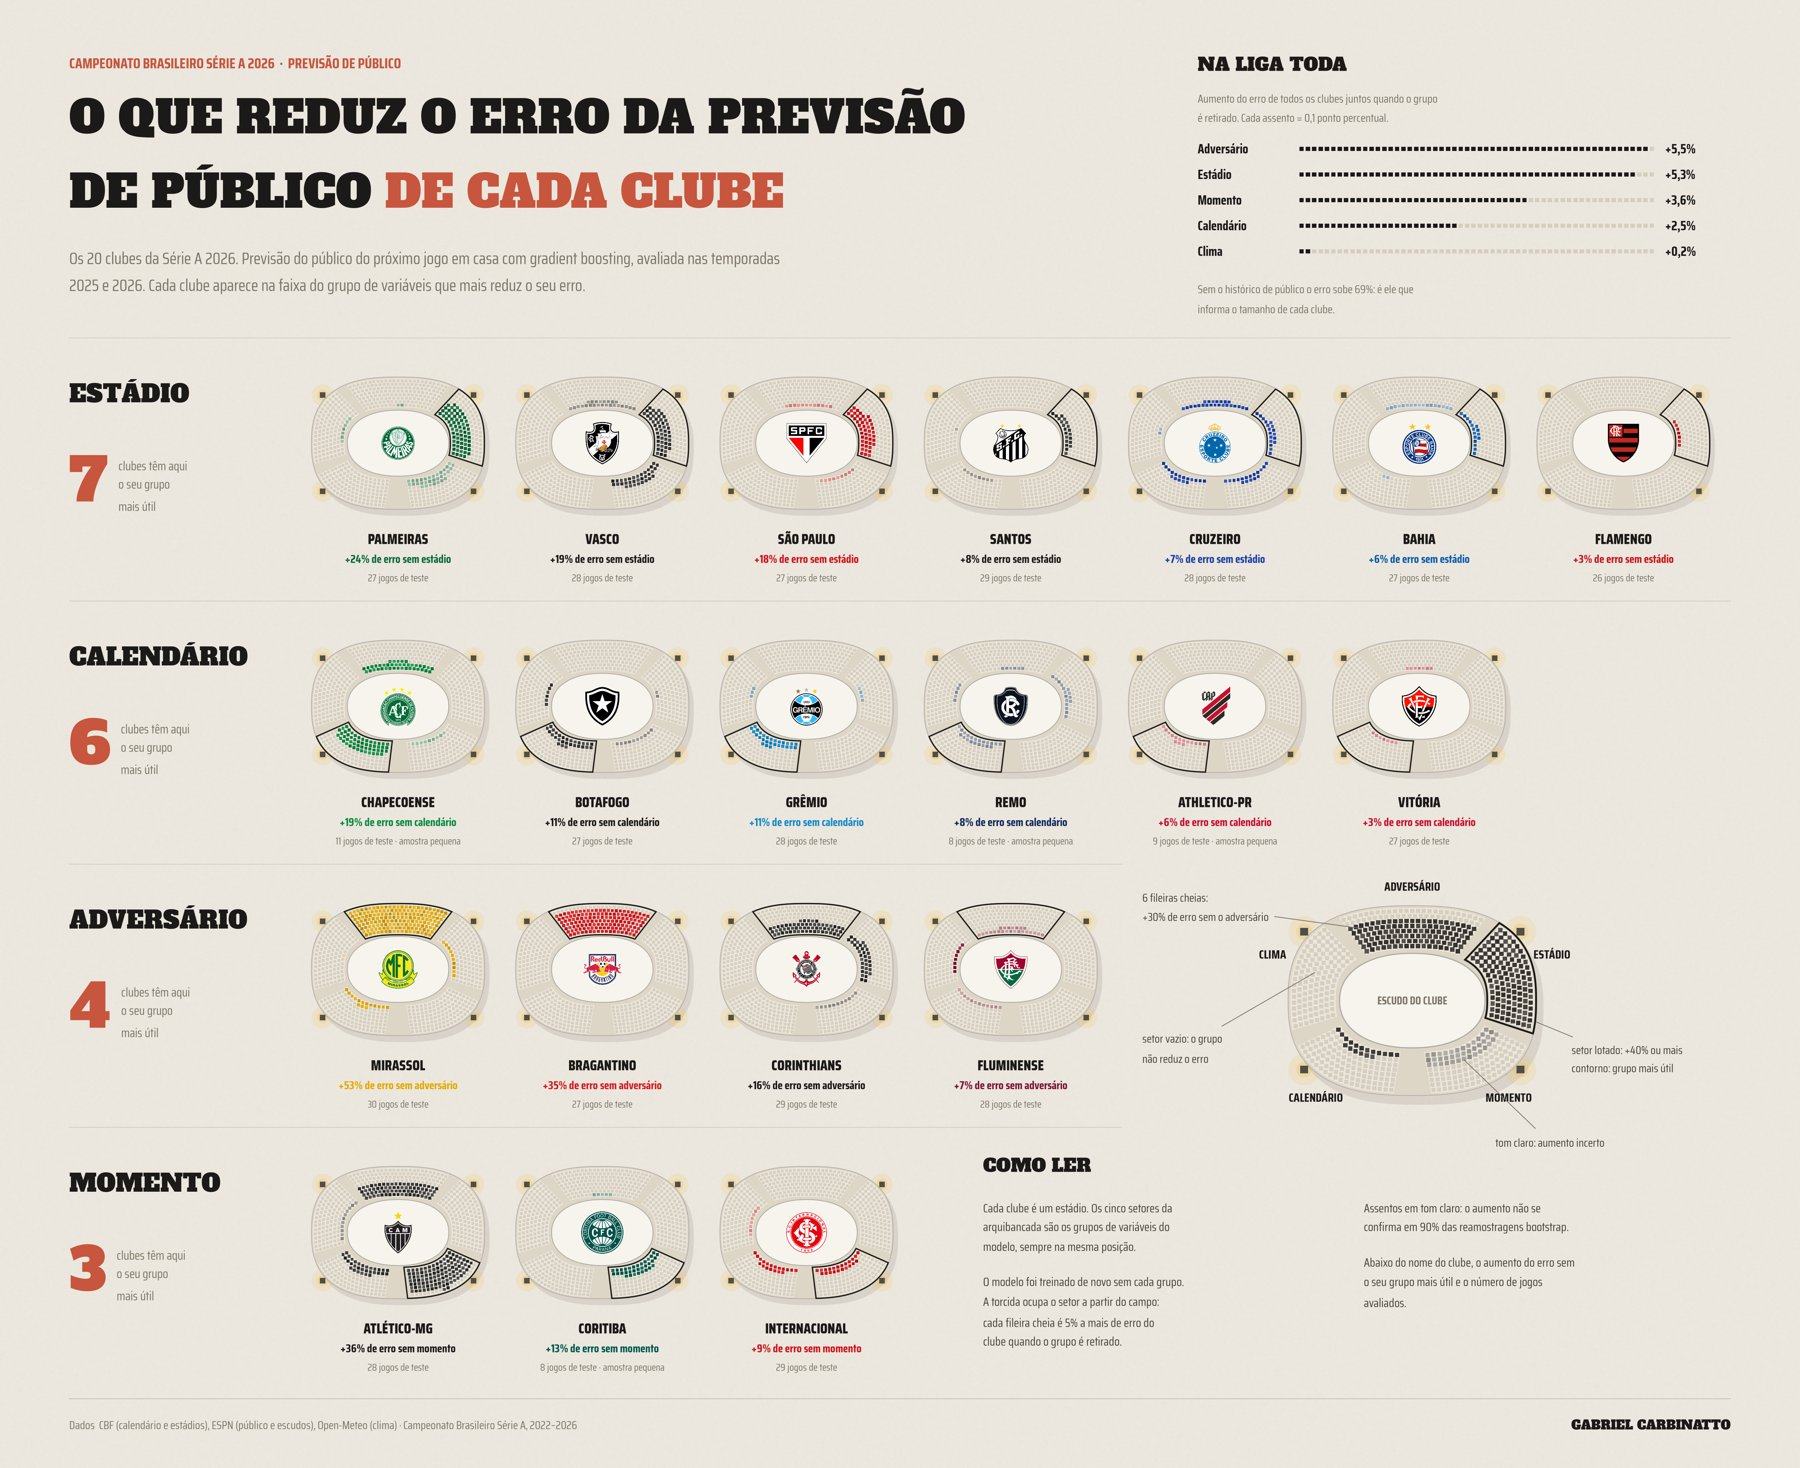

In [6]:
DPI = 200
W, H = 26, 21.2
fig = plt.figure(figsize=(W, H), dpi=DPI, facecolor=BG)
ax = fig.add_axes([0, 0, 1, 1])
ax.set_xlim(0, W)
ax.set_ylim(0, H)
ax.set_aspect("equal")
ax.axis("off")

renderer = fig.canvas.get_renderer()


def extent(text):
    box = text.get_window_extent(renderer)
    (x0, y0), (x1, y1) = ax.transData.inverted().transform([(box.x0, box.y0), (box.x1, box.y1)])
    return x0, y0, x1, y1


# textura de papel
grain = np.random.default_rng(3).normal(0, 1, (990, 1300))
ax.imshow(grain, extent=(0, W, 0, H), cmap="Greys", alpha=0.035, interpolation="bilinear", zorder=-1, aspect="auto")

# cabeçalho
ax.text(1.0, H - 0.75, "CAMPEONATO BRASILEIRO SÉRIE A 2026  ·  PREVISÃO DE PÚBLICO", fontsize=15, fontweight="bold", color=ACCENT, family=FONT, va="top")
line1 = ax.text(1.0, H - 1.25, "O QUE REDUZ O ERRO DA PREVISÃO", fontsize=47, color=INK, family=DISPLAY, va="top")
_, y_bottom, _, _ = extent(line1)
line2a = ax.text(1.0, y_bottom - 0.18, "DE PÚBLICO ", fontsize=47, color=INK, family=DISPLAY, va="top")
_, _, x_end, _ = extent(line2a)
ax.text(x_end, y_bottom - 0.18, "DE CADA CLUBE", fontsize=47, color=ACCENT, family=DISPLAY, va="top")
ax.text(1.0, H - 3.55, "Os 20 clubes da Série A 2026. Previsão do público do próximo jogo em casa com gradient boosting, avaliada nas temporadas\n"
        "2025 e 2026. Cada clube aparece na faixa do grupo de variáveis que mais reduz o seu erro.", fontsize=17, color=MUTED, family=FONT, va="top", linespacing=1.05)

# resumo da liga, no canto superior direito
lx, ly = 17.3, H - 0.75
ax.text(lx, ly, "NA LIGA TODA", fontsize=19, color=INK, family=DISPLAY, va="top")
ax.text(lx, ly - 0.55, "Aumento do erro de todos os clubes juntos quando o grupo\né retirado. Cada assento = 0,1 ponto percentual.", fontsize=12, color=MUTED, family=FONT, va="top", linespacing=1.05)
for k, group in enumerate(["opponent", "venue", "form", "calendar", "weather"]):
    yy = ly - 1.4 - k * 0.37
    v = overall.loc[group, "relative_increase"]
    ax.text(lx, yy, NAME[group], fontsize=13.5, fontweight="bold", color=INK, family=FONT, va="center")
    n = 56
    lit = int(round(max(v, 0) / 0.001))
    xs = lx + 1.5 + np.arange(n) * 0.092
    ax.scatter(xs, np.full(n, yy), s=(0.064 * 72) ** 2, marker="s", color=[INK if i < lit else EMPTY for i in range(n)], linewidths=0)
    ax.text(lx + 1.5 + n * 0.092 + 0.1, yy, f"+{v * 100:.1f}%".replace(".", ","), fontsize=13.5, fontweight="bold", color=INK, family=FONT, va="center")
ax.text(lx, ly - 3.3, "Sem o histórico de público o erro sobe 69%: é ele que\ninforma o tamanho de cada clube.", fontsize=12, color=MUTED, family=FONT, va="top", linespacing=1.05)

# faixas, uma por grupo mais útil
order = ["venue", "calendar", "opponent", "form"]
s = 1.22
x_first, step_x = 5.75, 2.95
band_top = H - 5.05
band_h = 3.8
for j, group in enumerate(order):
    cy = band_top - 1.35 - j * band_h
    clubs = sorted(increase.index[best.eq(group)], key=lambda c: -increase.loc[c, group])
    ax.plot([1.0, W - 1.0 if j < 2 else 16.2], [cy + 1.52, cy + 1.52], color=mix(INK, 0.86), lw=0.8)
    ax.text(1.0, cy + 0.95, NAME[group].upper(), fontsize=25, color=INK, family=DISPLAY, va="top")
    numeral = ax.text(1.0, cy + 0.05, str(len(clubs)), fontsize=62, color=ACCENT, family=DISPLAY, va="top")
    _, _, nx, _ = extent(numeral)
    ax.text(nx + 0.15, cy - 0.2, "clubes têm aqui\no seu grupo\nmais útil", fontsize=13, color=MUTED, family=FONT, va="top", linespacing=1.0)
    for i, club in enumerate(clubs):
        cx = x_first + i * step_x
        stadium(ax, cx, cy, s, increase.loc[club].to_dict(), share.loc[club].to_dict(), CLUB_COLOR[club], club=club, best_group=group, show_best_value=False)
        ax.text(cx, cy - 1.0 * s, SHORT.get(club, club).upper(), ha="center", va="top", fontsize=15, fontweight=800, color=INK, family=FONT)
        value = increase.loc[club, group]
        ax.text(cx, cy - 1.0 * s - 0.32, f"+{value * 100:.0f}% de erro sem {NAME[group].lower()}", ha="center", va="top", fontsize=12, fontweight="bold",
                color=CLUB_COLOR[club] if CLUB_COLOR[club] != "#1f1f1f" else INK, family=FONT)
        note = f"{matches[club]} jogos de teste" + (" · amostra pequena" if matches[club] < 12 else "")
        ax.text(cx, cy - 1.0 * s - 0.61, note, ha="center", va="top", fontsize=10.5, color=MUTED, family=FONT)

# estádio-chave
kx, ky = 20.4, band_top - 1.35 - 2 * band_h - 0.45
example = {"opponent": 0.30, "venue": 0.40, "form": 0.15, "calendar": 0.075, "weather": 0.0}
stadium(ax, kx, ky, 1.75, example, {g: (0.95 if g != "form" else 0.5) for g in GROUPS}, "#3d3a35", best_group="venue", labels=True, show_best_value=False)
ax.text(kx, ky, "ESCUDO DO CLUBE", ha="center", va="center", fontsize=11.5, color=MUTED, family=FONT, fontweight="bold", zorder=9)


def note(x, y, text, xy, ha="left"):
    ax.annotate(text, xy=xy, xytext=(x, y), fontsize=12, color="#45413b", family=FONT, ha=ha, va="center", linespacing=1.05,
                arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8, shrinkA=4, shrinkB=2), zorder=10)


ox, oy = arc(kx, ky, np.deg2rad(112), 0.6, 1.75)
note(kx - 3.9, ky + 1.35, "6 fileiras cheias:\n+30% de erro sem o adversário", (ox, oy))
vx, vy = arc(kx, ky, np.deg2rad(-8), 1.04, 1.75)
note(kx + 2.3, ky - 0.85, "setor lotado: +40% ou mais\ncontorno: grupo mais útil", (vx, vy))
fx, fy = arc(kx, ky, np.deg2rad(-62), 0.3, 1.75)
note(kx + 1.2, ky - 2.05, "tom claro: aumento incerto", (fx, fy))
wx, wy = arc(kx, ky, np.deg2rad(-198), 0.5, 1.75)
note(kx - 3.9, ky - 0.7, "setor vazio: o grupo\nnão reduz o erro", (wx, wy))

# como ler
ry = band_top - 1.35 - 3 * band_h + 1.15
ax.text(14.2, ry, "COMO LER", fontsize=19, color=INK, family=DISPLAY, va="top")
how = [
    "Cada clube é um estádio. Os cinco setores da arquibancada são os grupos de variáveis do modelo, sempre na mesma posição.",
    "O modelo foi treinado de novo sem cada grupo. A torcida ocupa o setor a partir do campo: cada fileira cheia é 5% a mais de erro do clube quando o grupo é retirado.",
    "Assentos em tom claro: o aumento não se confirma em 90% das reamostragens bootstrap.",
    "Abaixo do nome do clube, o aumento do erro sem o seu grupo mais útil e o número de jogos avaliados.",
]
y_next = ry - 0.65
for k, paragraph in enumerate(how):
    col_x = 14.2 + (k // 2) * 5.5
    y0 = ry - 0.65 if k % 2 == 0 else y_next
    t = ax.text(col_x, y0, textwrap.fill(paragraph, 46), fontsize=12.5, color="#45413b", family=FONT, va="top", linespacing=1.05)
    y_next = extent(t)[1] - 0.22

# rodapé
ax.plot([1.0, W - 1.0], [1.0, 1.0], color=mix(INK, 0.8), lw=0.8)
ax.text(1.0, 0.62, "Dados  CBF (calendário e estádios), ESPN (público e escudos), Open-Meteo (clima) · Campeonato Brasileiro Série A, 2022–2026",
        fontsize=12, color=MUTED, family=FONT, va="center")
ax.text(W - 1.0, 0.62, "GABRIEL CARBINATTO", fontsize=13, color=INK, family=DISPLAY, va="center", ha="right")

fig.savefig(VIZ / POSTER, dpi=DPI, facecolor=BG)
plt.close(fig)
preview = Image.open(VIZ / POSTER)
preview.thumbnail((1800, 1800))
buffer = BytesIO()
preview.convert("RGB").save(buffer, "JPEG", quality=85)
display(IPImage(data=buffer.getvalue()))

## **6. Exportação e auditoria**

| arquivo | conteúdo |
|---|---|
| `viz/7_01_arquibancadas_serie_a_2026.png` | pôster com os 20 clubes da Série A 2026 |
| `data/processed/ablation/clubs_2026.csv` | aumento do erro e proporção bootstrap por clube de 2026 e grupo |

A auditoria confirma que o pôster tem os 20 clubes da temporada, que todos têm escudo e que cada clube aparece em exatamente uma faixa.

In [7]:
table.to_csv(PROCESSED / "ablation" / "clubs_2026.csv", index=False)
assert len(CLUBS) == 20, f"A temporada {SEASON} deveria ter 20 clubes, encontrados {len(CLUBS)}"
assert crests.all(), f"Clubes sem escudo: {list(crests.index[~crests])}"
assert best.isin(GROUPS).all() and best.index.is_unique, "Cada clube deve ter um único grupo mais útil"
assert (VIZ / POSTER).exists(), "O pôster não foi gravado"
print(f"pôster: {(VIZ / POSTER).relative_to(ROOT)} | {Image.open(VIZ / POSTER).size}")

pôster: viz/7_01_arquibancadas_serie_a_2026.png | (5200, 4240)
